# Day 1 — A New Way of Thinking, and Your First Model

**Project:** Automatic Incident & Log Agent (chosen today) · **Dataset:** Loghub HDFS_v1

1. The ML landscape: which kind of problem is ours?
2. Just enough statistics
3. Why vectorised NumPy beats a Python loop
4. Gradient descent from scratch (loss curve, learning rate)
5. Logistic regression from scratch, matched against scikit-learn

In [1]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression

from logagent.splits import load_blocks, time_split

SEED = 42
rng = np.random.default_rng(SEED)
df = load_blocks()

## 1. The ML landscape: picking an approach

| Question | Our answer |
|---|---|
| Do we have the right answers (labels)? | Yes, every HDFS block is labelled normal/anomaly → **supervised** learning |
| Predict a category or a number? | Anomaly yes/no → **classification** (binary) |
| Where would *unsupervised* fit? | Grouping similar log lines with no labels (Day 7, K-Means) |
| Where would *regression* fit? | Predicting a number, e.g. how many events a block will produce (Day 4) |

**ML code vs. normal code:** a rule like `if errors > 5: alert()` is code we write. Here the model *learns* the rule from 400k
labelled examples, so its answers are probabilities, and it can be wrong even with zero bugs.

**Project choice:** Automatic Incident & Log Agent. It has real labelled data, rare failures, timestamps, and maps onto every day
of the course, ending with an agent that investigates incidents through MCP tools.

## 2. Just enough statistics
**Mean** = typical value, **variance / std** = how spread out values are, **distribution** = the full shape.
Logs are typical of real data: heavily *skewed*, so the mean alone can mislead.

mean=19.43  median=19  variance=26.81  std=5.18  max=298
anomaly rate (mean of a 0/1 label = a probability): 2.928%


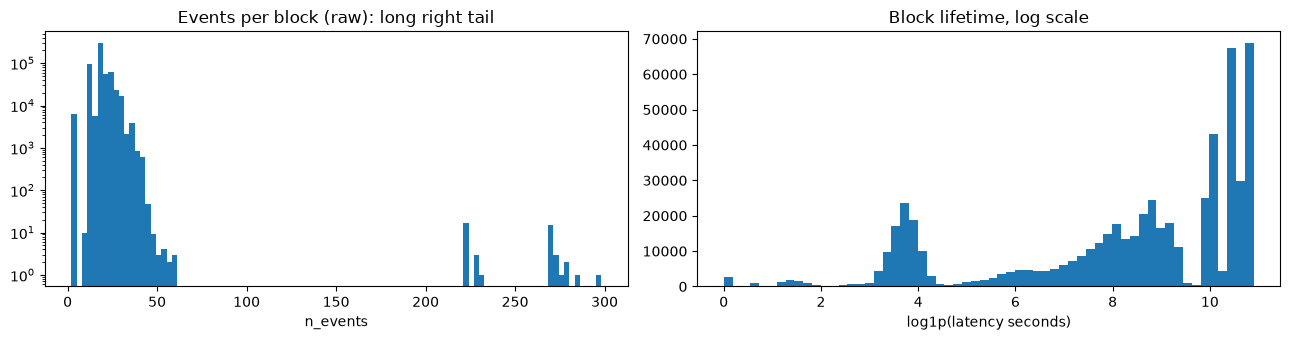

In [2]:
x = df["n_events"]
print(f"mean={x.mean():.2f}  median={x.median():.0f}  variance={x.var():.2f}  std={x.std():.2f}  max={x.max()}")
print(f"anomaly rate (mean of a 0/1 label = a probability): {df['label'].mean():.3%}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(x, bins=100); axes[0].set(title="Events per block (raw): long right tail", xlabel="n_events", yscale="log")
axes[1].hist(np.log1p(df["latency"]), bins=60); axes[1].set(title="Block lifetime, log scale", xlabel="log1p(latency seconds)")
plt.tight_layout()

## 3. Vectorisation: why NumPy is fast
Same dot product, two ways. The Python loop handles one number at a time through the interpreter. NumPy's `@` runs in compiled C
and uses the CPU's **SIMD** instructions (several numbers per instruction) on contiguous, cache-friendly memory.

In [3]:
n = 1_000_000
a, b = rng.random(n), rng.random(n)
al, bl = a.tolist(), b.tolist()

def loop_dot(u, v):
    total = 0.0
    for i in range(len(u)):
        total += u[i] * v[i]
    return total

def best_of(fn, repeats=5):
    times = []
    for _ in range(repeats):
        t = time.perf_counter(); r = fn(); times.append(time.perf_counter() - t)
    return min(times), r

t_loop, r_loop = best_of(lambda: loop_dot(al, bl))
t_np, r_np = best_of(lambda: a @ b)
print(f"python loop: {t_loop * 1000:8.2f} ms   result {r_loop:.4f}")
print(f"numpy  @   : {t_np * 1000:8.2f} ms   result {r_np:.4f}")
print(f"speed-up   : {t_loop / t_np:,.0f}x  (same answer: {np.isclose(r_loop, r_np)})")

python loop:    46.12 ms   result 249818.4930
numpy  @   :     1.67 ms   result 249818.4930
speed-up   : 28x  (same answer: True)


## 4. Gradient descent from scratch
Training is a loop:
1. **predict** with the current **weights**
2. measure the error with a **loss function**
3. compute the **gradient** (which direction makes the loss go up)
4. step the weights the *other* way, by the **learning rate**
5. repeat

Warm-up on data where we know the true answer: `y = 3x + 2 + noise`. Loss = mean squared error (MSE).

learned w=2.966, b=2.016   (true: 3, 2)


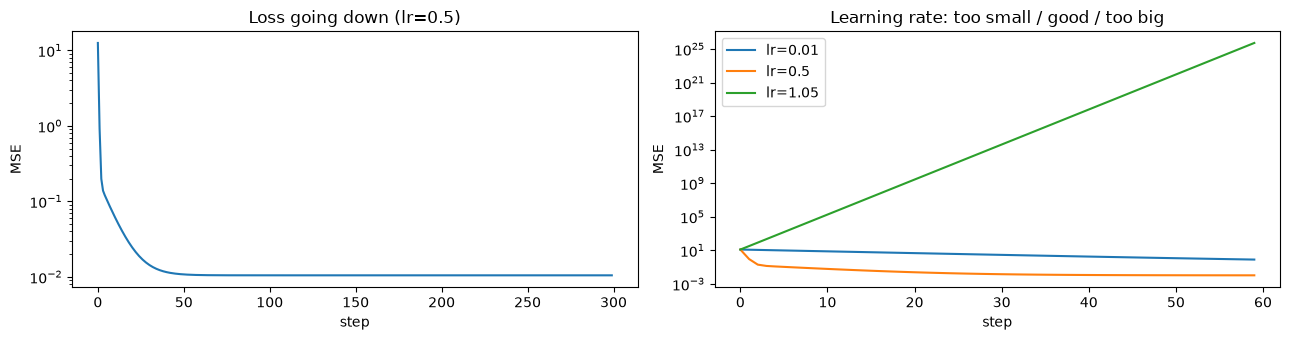

In [4]:
X1 = rng.random(500)
y1 = 3 * X1 + 2 + rng.normal(0, 0.1, 500)

def gradient_descent(lr, steps=300):
    w, b, losses = 0.0, 0.0, []
    for _ in range(steps):
        err = (w * X1 + b) - y1               # 1. predict, then error
        losses.append((err ** 2).mean())      # 2. MSE loss
        grad_w = 2 * (err * X1).mean()        # 3. gradients
        grad_b = 2 * err.mean()
        w -= lr * grad_w                      # 4. step downhill
        b -= lr * grad_b
    return w, b, losses

w, b, losses = gradient_descent(lr=0.5)
print(f"learned w={w:.3f}, b={b:.3f}   (true: 3, 2)")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].plot(losses); axes[0].set(title="Loss going down (lr=0.5)", xlabel="step", ylabel="MSE", yscale="log")
for lr in [0.01, 0.5, 1.05]:
    axes[1].plot(gradient_descent(lr, 60)[2], label=f"lr={lr}")
axes[1].set(title="Learning rate: too small / good / too big", xlabel="step", ylabel="MSE", yscale="log"); axes[1].legend()
plt.tight_layout()

Too small → it crawls. Too big → each step overshoots the minimum and the loss **explodes**. Choosing the learning rate is the first
hyperparameter you'll tune (Optuna does it for us on Day 3).

## 5. Logistic regression from scratch (on the project data)
For yes/no problems:
- score `z = X·w + b`
- **sigmoid** `σ(z) = 1 / (1 + e^-z)` turns any score into a probability between 0 and 1
- loss = **cross-entropy** `-mean(y·log p + (1-y)·log(1-p))`, which punishes confident mistakes hard
- the gradient is simply `Xᵀ(p - y) / n` (the same loop as above)

**Features:** counts of a few common events in a block's first 8 log events, plus the time elapsed (log-scaled and standardised).
We leave out rare events that appear *only* in anomalies: they separate the classes perfectly, so an unregularised model's
weights would grow without limit and never converge. (Regularisation, Day 5, is the usual fix.)

converged after 14,438 steps, final loss 0.10093


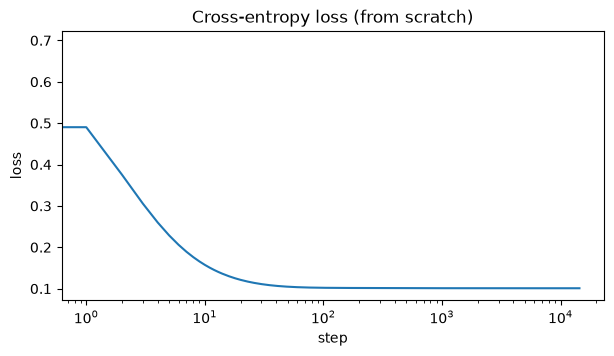

In [5]:
train, val, test = time_split(df)
cols = ["early_E5", "early_E9", "early_E11", "early_E22", "early_E26", "early_elapsed"]
sample = train.sample(50_000, random_state=SEED)       # a sample keeps the from-scratch loop quick

X = np.log1p(sample[cols].to_numpy(float))
mu, sd = X.mean(axis=0), X.std(axis=0)
X = (X - mu) / sd                                      # standardise: every feature on the same scale
y = sample["label"].to_numpy(float)

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def cross_entropy(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

w, b, lr, history = np.zeros(X.shape[1]), 0.0, 1.0, []
for step in range(50_000):
    p = sigmoid(X @ w + b)
    history.append(cross_entropy(y, p))
    err = p - y
    grad_w, grad_b = X.T @ err / len(y), err.mean()
    w -= lr * grad_w
    b -= lr * grad_b
    if np.sqrt(grad_w @ grad_w + grad_b ** 2) < 1e-8:   # converged = the slope is (almost) flat
        break
print(f"converged after {step + 1:,} steps, final loss {history[-1]:.5f}")

plt.figure(figsize=(7, 3.5)); plt.plot(history); plt.xscale("log")
plt.title("Cross-entropy loss (from scratch)"); plt.xlabel("step"); plt.ylabel("loss");

In [6]:
# Same model with scikit-learn. C=np.inf means "no regularisation", like our from-scratch version.
sk = LogisticRegression(C=np.inf, max_iter=10_000, tol=1e-12).fit(X, y)

coef = pd.DataFrame({"from scratch": np.r_[w, b], "scikit-learn": np.r_[sk.coef_[0], sk.intercept_[0]]},
                    index=cols + ["intercept"])
coef["abs diff"] = (coef["from scratch"] - coef["scikit-learn"]).abs()
print("coefficients match:", np.allclose(coef["from scratch"], coef["scikit-learn"], atol=1e-5))
coef.round(6)

coefficients match: True


,from scratch,scikit-learn,abs diff
early_E5,-0.608286,-0.608282,0.000003
early_E9,-0.675775,-0.675782,0.000007
early_E11,-0.893763,-0.893767,0.000004
early_E22,-0.032110,-0.032110,0.000000
early_E26,-1.329562,-1.329571,0.000010
early_elapsed,0.043206,0.043206,0.000000
intercept,-3.739688,-3.739688,0.000000


**Reading the coefficients** (features are standardised, so sizes are comparable): a **negative** weight pushes towards
*normal*. Blocks whose first events include the usual write-pipeline events (E9, E11, E26) are less likely to fail; a block
missing them is suspicious. The large negative intercept reflects how rare anomalies are (~3%).

In [7]:
# How useful is it? Probabilities on the validation period (never seen in training).
from sklearn.metrics import average_precision_score
Xv = (np.log1p(val[cols].to_numpy(float)) - mu) / sd
p_val = sigmoid(Xv @ w + b)
print(f"validation PR-AUC = {average_precision_score(val['label'], p_val):.3f}   (random guessing ≈ {val['label'].mean():.3f})")

validation PR-AUC = 0.425   (random guessing ≈ 0.030)


## End-of-day checklist
- [x] Problem framed: supervised, binary classification; project chosen
- [x] Basic statistics of the data (mean, variance, skewed distributions)
- [x] Vectorised NumPy clearly beats the Python loop (speed-up measured above)
- [x] Gradient descent from scratch with a falling loss curve, plus the effect of the learning rate
- [x] Logistic regression from scratch converges and matches scikit-learn's coefficients

Next (Day 2): explore the data properly, build a preprocessing pipeline, and split it without leakage.